# 📘 **Week 12: Text Representation and Feature Extraction**

**Business Data and Text Mining — BA3002**  
**BS Business Analytics | Fall 2026 | Sections A and B**

---

**👨‍🏫 Dr. Usama Arshad**  
Assistant Professor (Business Analytics), FAST-NUCES Islamabad  
Director & Founder, CRADLE Lab — Computational Research in AI, Data Science, and Ledger Engineering  
[Website](https://usamajanjua.com) · [GitHub](https://github.com/usamajanjua9)

### 🎯 **Learning Goals**

- Explain why text is represented by numerical features.
- Build and interpret a document-term matrix using a fixed vocabulary.
- Distinguish Bag of Words, term frequency, and TF-IDF.
- Calculate a small cosine-similarity example and interpret document rankings.
- Explain what word embeddings represent and how they differ from count-based features.
- Recognize limits involving word order, negation, unseen words, and evaluation leakage.

### 🧭 **Topics Covered This Week**

| Required topic | Where to study it | Learning outcome |
|---|---|---|
| [Converting text into numerical features](#section-1) | Section 1 | Explain a feature and a document vector |
| [Document-Term Matrix](#section-3) | Section 3 | Read rows, columns, values, and dimensions |
| [Bag of Words (BoW)](#section-2) | Section 2 | Count terms using a shared vocabulary |
| [Term Frequency and TF-IDF](#section-4) | Section 4 | Distinguish local frequency from corpus-wide rarity |
| [Vocabulary and feature matrices](#section-5) | Section 5 | Keep column meanings fixed and handle unseen words |
| [Cosine similarity](#section-6) | Section 6 | Compare vector directions and interpret scores |
| [Document similarity](#section-7) | Section 7 | Retrieve related documents and inspect the evidence |
| [Introduction to word embeddings](#section-8) | Section 8 | Explain learned dense vectors and their limitations |

**Learning order:** Concept → small worked example → business interpretation → guided Python lab.

[💻 Go to the lab](#lab)

> All customer comments and numerical scenarios are synthetic teaching examples. Week 11 explained text preparation; this week uses already prepared examples to focus on representation. The notebook runs independently and does not require the earlier notebooks or an external dataset.

![Week 11 learning pathway](https://media.licdn.com/dms/image/v2/D4D12AQEkfi4f6j4Rjw/article-cover_image-shrink_720_1280/B4DZiLAKPcH4AI-/0/1754678745184?e=2147483647&v=beta&t=TU5BaqSn-ykTZvW0C016ECAMKmEM7NbJRRfPbZ-cpO0)

<a id="section-1"></a>

---

## 1. **From Business Text to Numerical Features**

### 🔹 **1.1 Why Do We Need Numbers?**

**Definition**  
A numerical feature is a measurable property of a document. A text representation turns chosen properties into numbers that an algorithm can compare.

**Example**  
For “delivery late,” we can record the count of **delivery = 1**, **late = 1**, and **refund = 0**. These numbers describe selected words; they do not capture every part of the meaning.

**🚨 Problem**  
Many analytical methods operate on numerical arrays, not directly on written sentences. Assigning an arbitrary number to a whole sentence does not create a useful measure of meaning.

**✅ Solution**  
Choose features that support the question: word counts for an inspectable baseline, TF-IDF for distinctive wording, or suitable learned representations for semantic matching.

**Think about it:** Would assigning review IDs 101 and 102 mean the two reviews have similar meanings? Why not?

### 🔹 **1.2 Document, Token, Feature, and Vector**

**Definition**  
A document is one unit of text. Tokens are its chosen units. Features are the measurements or dimensions used to represent it. A vector is the ordered list of numerical feature values.

**Example**  
| Term | In a review-analysis project |
|---|---|
| Document | One customer review |
| Token | One word such as `delivery` |
| Feature | The count or weight of `delivery` |
| Vector | Values such as `[1, 1, 0]` |
| Corpus | The complete collection of reviews |

With columns `[delivery, late, refund]`, `[1, 1, 0]` means one delivery mention, one late mention, and no refund mention.

**🚨 Problem**  
The vector `[1, 1, 0]` is ambiguous if its column meanings are missing.

**✅ Solution**  
Save feature names in order and keep document IDs attached to rows. The same position must mean the same feature for every document.

### 🔹 **1.3 Preprocessing and Representation Are Different**

**Definition**  
Preprocessing prepares the text. Representation converts the prepared text into numerical features.

**Example**  
Week 11: `<p>DELIVERY late!</p>` becomes a selected token view such as `[delivery, late]`. Week 12: those tokens become a row of counts or weights.

**🚨 Problem**  
Cleaning does not automatically produce a numerical matrix. Also, changing the tokenization policy changes the matrix.

**✅ Solution**  
Keep the chosen preprocessing policy fixed when comparing representations. This lab uses lowercase, single-sentence examples and retains words such as **not**.

### 🔹 **1.4 Start with a Business Question**

**Definition**  
A representation is useful when it helps answer a specific question, not simply because it is sophisticated.

**Example**  
| Business question | Useful starting point | What to inspect |
|---|---|---|
| Which words occur in complaints? | Count matrix | Counts and document coverage |
| Which comments share distinctive wording? | TF-IDF and cosine similarity | Top matches and raw text |
| Which tickets describe the same issue using different words? | Lexical baseline, then evaluated embeddings | Meaning, not only shared words |
| Which product aspects recur? | Unigrams plus selected phrases | Product context and mixed opinions |

**🚨 Problem**  
A system can find similar words while missing the business issue.

**✅ Solution**  
Define what counts as a useful match before selecting a representation. A related topic, the same problem, and the same sentiment are different matching goals.

<a id="section-2"></a>

---

## 2. **Bag of Words and Vocabulary**

### 🔹 **2.1 What Is Bag of Words?**

**Definition**  
Bag of Words represents a document using occurrences of terms in a vocabulary. The simplest version counts words and ignores their order.

**Example**  
We will use three short documents for hand calculations:

| ID | Prepared text |
|---|---|
| D1 | delivery late |
| D2 | delivery fast |
| D3 | refund late late |

Across the corpus, the vocabulary is **delivery, fast, late, refund**. These are four distinct terms, even though words repeat.

**🚨 Problem**  
The documents have different words and lengths, so their raw token lists cannot be compared position by position.

**✅ Solution**  
Use one shared vocabulary. Create one value for every vocabulary term in every document, including zero for terms that are absent.

### 🔹 **2.2 Build a Count Vector by Hand**

**Definition**  
For a count-based BoW vector, each value is the number of times its vocabulary term appears in that document.

**Example**  
Vocabulary order: **[delivery, fast, late, refund]**.

| Document | Step-by-step count | Vector |
|---|---|---|
| D1: delivery late | delivery 1; fast 0; late 1; refund 0 | `[1, 0, 1, 0]` |
| D2: delivery fast | delivery 1; fast 1; late 0; refund 0 | `[1, 1, 0, 0]` |
| D3: refund late late | delivery 0; fast 0; late 2; refund 1 | `[0, 0, 2, 1]` |

**🚨 Problem**  
Counting each word only once would lose repetition: D3 contains **late twice**.

**✅ Solution**  
Be explicit about the representation. A count value of 2 records two occurrences; it does not mean two different customers mentioned the word.

### 🔹 **2.3 Counts, Binary Presence, and Phrases**

**Definition**  
Count BoW records repetitions. Binary BoW records only whether a term appears. An n-gram vocabulary can include neighboring word sequences as features.

**Example**  
| Representation | D3: “refund late late” |
|---|---|
| Word counts | late = 2; refund = 1 |
| Binary word presence | late = 1; refund = 1 |
| Bigram counts | refund late = 1; late late = 1 |

A feature can be a phrase such as **not good**, not only a single word.

**🚨 Problem**  
Binary values hide repetition; unigram counts hide local word order. Adding many phrases can make the vocabulary much larger.

**✅ Solution**  
Choose the simplest representation that preserves the information needed. Build phrases inside appropriate sentence and document boundaries; do not join separate reviews.

### 🔹 **2.4 What Bag of Words Misses**

**Definition**  
Unigram BoW records which terms occur and how often, but not their full arrangement or meaning in context.

**Example**  
“customer helps agent” and “agent helps customer” have identical unigram counts. “delivery late” and “delivery not late” share two words but express different delivery experiences.

**🚨 Problem**  
High overlap does not prove agreement. Also, “refund” and “reimbursement” are separate vocabulary features despite their related meanings.

**✅ Solution**  
Inspect source text, preserve negation, and consider phrase features or learned representations when needed. None of these choices removes the need to evaluate the actual task.

<a id="section-3"></a>

---

## 3. **Document-Term Matrix**

### 🔹 **3.1 Read the Rows and Columns**

**Definition**  
A document-term matrix (DTM) arranges document vectors into a table: documents are rows and terms are columns.

**Example**  
| Document | delivery | fast | late | refund |
|---|---:|---:|---:|---:|
| D1 | 1 | 0 | 1 | 0 |
| D2 | 1 | 1 | 0 | 0 |
| D3 | 0 | 0 | 2 | 1 |

This matrix has **3 rows × 4 columns**. The D3/late cell is 2. The D1/refund cell is 0.

**🚨 Problem**  
Confusing row counts with column counts can lead to incorrect conclusions about corpus size.

**✅ Solution**  
Read the shape as **number of documents × number of features**. A term-document matrix is the transposed orientation; always inspect labels.

### 🔹 **3.2 DTM Is a Structure; BoW Is a Representation**

**Definition**  
The matrix is the container. BoW describes how selected terms represent documents. The values inside a DTM may be counts, binary presence, or weights.

**Example**  
The same three rows and four columns can hold raw counts or TF-IDF weights. Changing the values need not change which document or term each position represents.

**🚨 Problem**  
Treating “DTM,” “BoW,” and “TF-IDF” as interchangeable names hides important choices.

**✅ Solution**  
State both the layout and the weighting: for example, **a document-term matrix containing unigram counts**, or **a TF-IDF feature matrix**.

### 🔹 **3.3 Sparse Matrices and Storage**

**Definition**  
A sparse matrix stores mainly the nonzero entries instead of explicitly storing every zero. A dense matrix stores a value at every position.

**Example**  
The 3 × 4 teaching matrix has 12 positions and 6 nonzero entries. Its nonzero density is 6 ÷ 12 = 50%. Larger text vocabularies often produce much lower densities.

**🚨 Problem**  
A real matrix with 100,000 documents and 50,000 terms has 5 billion possible positions. Displaying or converting all of it to a dense array can exhaust memory.

**✅ Solution**  
Keep large text matrices sparse. The lab calls `.toarray()` only for tiny teaching tables. Preview selected rows and columns in larger projects.

### 🔹 **3.4 Rows, Columns, and Useful Checks**

**Definition**  
A correct matrix preserves record alignment and consistent feature meanings.

**Example**  
For the hand example, row sums are 2, 2, and 3. Column totals are delivery 2, fast 1, late 3, refund 1. There are 7 total token occurrences.

**🚨 Problem**  
A table can look plausible even when rows have been shuffled or labels are attached in the wrong order.

**✅ Solution**  
Check matrix shape, row IDs, vocabulary order, nonnegative counts, and a few hand-calculated cells. Preserve the order of the input documents when attaching labels.

<a id="section-4"></a>

---

## 4. **Term Frequency and TF-IDF**

### 🔹 **4.1 Term Frequency: Count Within One Document**

**Definition**  
Term frequency (TF) describes how often a term occurs within a document. Several conventions exist, so state the one being used.

**Example**  
For D3 = “refund late late”:

| TF convention | late | refund | Meaning |
|---|---:|---:|---|
| Raw count | 2 | 1 | Number of occurrences |
| Relative frequency | 2/3 | 1/3 | Count divided by document token count |
| Binary presence | 1 | 1 | Present or absent |

The main TF-IDF lab uses **raw counts** before applying IDF and vector normalization.

**🚨 Problem**  
A long comment may contain a term more often simply because it has more words. Also, two implementations can use different TF conventions.

**✅ Solution**  
Do not assume TF always means relative frequency. Record whether counts, relative values, binary values, or sublinear counts are used. For an empty document, relative TF needs an explicit policy.

### 🔹 **4.2 Document Frequency and Inverse Document Frequency**

**Definition**  
Document frequency, df, counts how many documents contain a term at least once. Inverse document frequency, IDF, gives more weight to terms found in fewer documents.

**Example**  
In our three-document corpus:

| Term | Total occurrences | Document frequency |
|---|---:|---:|
| delivery | 2 | 2 |
| fast | 1 | 1 |
| late | 3 | 2 |
| refund | 1 | 1 |

**late** occurs three times but appears in only two documents.

**🚨 Problem**  
Using occurrence count as df overcounts repeated words inside one document.

**✅ Solution**  
Count presence once per document for df. A term can be frequent in one document yet relatively rare across the corpus.

### 🔹 **4.3 Calculate Smoothed IDF**

**Definition**  
This notebook uses the smoothed IDF convention implemented by the default scikit-learn TF-IDF weighting: **idf(t) = ln((1 + N) / (1 + df(t))) + 1**, where N is the number of fitted documents and ln is the natural logarithm.

**Example**  
With N = 3:

| Term | df | Calculation | IDF, rounded |
|---|---:|---|---:|
| delivery | 2 | ln(4/3) + 1 | 1.288 |
| fast | 1 | ln(4/2) + 1 | 1.693 |
| late | 2 | ln(4/3) + 1 | 1.288 |
| refund | 1 | ln(4/2) + 1 | 1.693 |

The added ones smooth the ratio; the final +1 keeps the weight of a term found in every document at 1 under this convention.

**🚨 Problem**  
Other books may use ln(N/df), without smoothing or the final +1. Their numerical values will differ.

**✅ Solution**  
Use one documented convention throughout a calculation. Do not compare values from different formulas as if they were identical.

### 🔹 **4.4 Multiply TF by IDF**

**Definition**  
An unnormalized TF-IDF weight is the selected TF value multiplied by the term’s IDF value.

**Example**  
For D3, using raw-count TF:

- late: 2 × 1.288 ≈ **2.575** using unrounded IDF internally.
- refund: 1 × 1.693 ≈ **1.693**.
- delivery and fast: 0, because they are absent.

D3 is approximately **[0, 0, 2.575, 1.693]** before vector normalization.

**🚨 Problem**  
A high weight is sometimes mistaken for positive sentiment, business severity, or causal importance.

**✅ Solution**  
Interpret it as a weighting of occurrence and corpus rarity under the selected method. Read the text and assess severity separately. Keep full precision during calculations; round only for display.

### 🔹 **4.5 L2 Normalization: Put Vectors on a Common Scale**

**Definition**  
L2 normalization divides each value in a nonzero vector by the square root of the sum of squared values. The resulting vector has length 1.

**Example**  
For D3’s unnormalized TF-IDF vector:

Length ≈ √(2.575² + 1.693²) ≈ **3.082**.

Normalized D3 ≈ **[0, 0, 0.836, 0.549]**.

This is **vector normalization**, which differs from the text normalization studied in Week 11.

**🚨 Problem**  
Relative TF divides by the number of tokens; L2 normalization divides by vector length. They are different operations. Rounded numbers may not have an exact length of 1.

**✅ Solution**  
State the operations in order: raw TF → smoothed IDF → multiplication → L2 normalization. Do not divide an all-zero vector by zero; keep it zero and flag its lack of usable features.

### 🔹 **4.6 Where TF-IDF Helps and Where It Does Not**

**Definition**  
TF-IDF is a useful lexical baseline: it emphasizes terms that distinguish documents within the fitted collection.

**Example**  
For a collection of delivery complaints, **delivery** may occur almost everywhere while **damaged**, **missing**, or **refund** distinguishes particular issues.

**🚨 Problem**  
A misspelling can be rare and receive a high IDF. Synonyms with no shared wording still occupy separate features. IDF also changes when the fitted collection changes.

**✅ Solution**  
Check rare terms, maintain a versioned vocabulary and IDF, and evaluate retrieved matches. TF-IDF is not a semantic guarantee and does not understand sarcasm.

<a id="section-5"></a>

---

## 5. **Vocabulary and Feature Matrices**

### 🔹 **5.1 The Vocabulary Defines the Columns**

**Definition**  
A vocabulary is the set of retained terms together with their mapping to feature positions.

**Example**  
For `[delivery, fast, late, refund]`, position 0 always represents delivery. A new document must use those same four positions, even if it contains only refund.

**🚨 Problem**  
Fitting a new vocabulary separately for each batch can change the column meanings or their number.

**✅ Solution**  
Fit the representation on the intended reference data and reuse it to transform later documents. Keep the feature names with every exported matrix.

### 🔹 **5.2 Fit, Transform, and Fit-Transform**

**Definition**  
Fitting learns the vocabulary and, for TF-IDF, document-frequency weights. Transforming uses those learned choices. Fit-transform performs both operations on the reference collection.

**Example**  
| Operation | What happens |
|---|---|
| `fit(reference_texts)` | Learn vocabulary and required weights |
| `transform(new_texts)` | Represent new texts using the learned feature space |
| `fit_transform(reference_texts)` | Learn and represent the reference texts together |

A search query should be transformed with the fitted document vectorizer, not fitted as a new collection.

**🚨 Problem**  
A query and the documents may have incompatible feature columns if fitted separately.

**✅ Solution**  
Use the same fitted vectorizer. In predictive evaluation, fit vocabulary and IDF on training data only; transform validation and test data without learning from them.

### 🔹 **5.3 Unseen Words and Zero Vectors**

**Definition**  
An out-of-vocabulary word is absent from the fitted vocabulary. A fixed count or TF-IDF vectorizer ignores it during transformation.

**Example**  
If the vocabulary contains delivery, fast, late, and refund, the new phrase “refund approved” keeps refund but cannot create an approved column. “quantum telescope” becomes a zero vector.

**🚨 Problem**  
A zero vector does not mean a neutral opinion or a meaningless sentence. It means no retained features matched.

**✅ Solution**  
Detect zero-feature documents and queries. Return a clear no-match result or review the representation. A vocabulary update requires refitting and regenerating compatible stored vectors.

### 🔹 **5.4 Control Vocabulary Size Deliberately**

**Definition**  
Vocabulary controls determine which terms or phrases become features.

**Example**  
| Option | Plain-language purpose | Caution |
|---|---|---|
| `min_df` | Exclude terms found in too few documents | Rare but serious complaints may disappear |
| `max_df` | Exclude terms found in too many documents | Frequent terms may still be useful |
| `max_features` | Limit the vocabulary size | This is not proof of business importance |
| `ngram_range` | Choose words and/or neighboring phrases | More phrases can increase sparsity |
| Tokenization and stop-word policy | Define what can become a term | Preserve meaningful words such as “not” |

Integer df thresholds refer to document counts; fractional thresholds refer to document proportions.

**🚨 Problem**  
Defaults can silently discard short tokens or make unhelpful vocabulary decisions for business identifiers.

**✅ Solution**  
Inspect extracted terms and a few transformed documents. Use simple settings in the teaching lab, then tune on appropriate development data for a real task.

<a id="section-6"></a>

---

## 6. **Cosine Similarity**

### 🔹 **6.1 Compare Direction Rather Than Magnitude**

**Definition**  
Cosine similarity compares the directions of two nonzero numerical vectors. It is their dot product divided by the product of their lengths.

**Example**  
**cosine(a, b) = (a · b) / (‖a‖ × ‖b‖)**

- Dot product: multiply values in corresponding positions, then add.
- Vector length: square each value, add, and take the square root.
- Corresponding positions must represent the same features.

**🚨 Problem**  
Euclidean distance or raw dot products can be strongly affected by vector magnitude. A repeated text has larger counts even when its term proportions are unchanged.

**✅ Solution**  
Use cosine when direction is the desired comparison. It does not solve all effects of document length or remove the need for suitable features.

### 🔹 **6.2 A Complete Hand Calculation**

**Definition**  
A manual example makes each part of the similarity formula visible.

**Example**  
Use count vectors D1 = `[1, 0, 1, 0]` and D2 = `[1, 1, 0, 0]`.

1. Dot product = (1×1) + (0×1) + (1×0) + (0×0) = **1**.
2. Length of D1 = √(1² + 1²) = **√2**.
3. Length of D2 = **√2**.
4. Cosine = 1 / (√2 × √2) = **0.5**.

D1 and D3 have count cosine 2 / √10 ≈ **0.632**. D2 and D3 have no shared terms, so their count cosine is **0**.

**🚨 Problem**  
A score of 0.5 is sometimes reported as “50% the same meaning.” That interpretation is not justified.

**✅ Solution**  
Report it as cosine similarity under a named representation. Changing from counts to TF-IDF changes the geometry and may change scores or ranking.

### 🔹 **6.3 Interpret the Score Carefully**

**Definition**  
For nonnegative count and TF-IDF vectors, cosine scores lie from 0 to 1. For general vectors that can have negative components, the mathematical range is −1 to 1.

**Example**  
| Score or situation | Interpretation |
|---|---|
| 1 | Same direction, not necessarily identical text |
| Near 1 | Strong directional alignment under these features |
| 0 with nonzero count vectors | No shared retained terms |
| Negative with general vectors | Opposing directions; not automatically opposite sentiment |
| A zero vector | Mathematical cosine is undefined because its length is zero |

The scikit-learn function returns 0 for comparisons involving a zero vector. We detect that case before interpreting query results.

**🚨 Problem**  
The same numeric threshold can behave differently across corpora and representations.

**✅ Solution**  
Do not set a universal “similar enough” score. Choose thresholds from reviewed examples of the actual task and report the representation.

### 🔹 **6.4 Similarity Does Not Establish Truth or Sentiment**

**Definition**  
Similarity is a relation between representations. It does not verify the claims in a document or prove that two writers share an opinion.

**Example**  
“delivery late” and “delivery not late” overlap strongly. The second comment explicitly negates lateness.

**🚨 Problem**  
A retrieval system could recommend the second comment as a complaint if it relies only on shared terms.

**✅ Solution**  
Show the original text beside scores, preserve not, and distinguish retrieval from opinion analysis. Human review or a separately evaluated task-specific method is needed for stronger decisions.

<a id="section-7"></a>

---

## 7. **Document Similarity in Business**

### 🔹 **7.1 Query-to-Document Similarity**

**Definition**  
Query-to-document similarity compares one query vector with each vector in a reference collection.

**Example**  
A support analyst searches for **refund pending**. The query is transformed with the fitted TF-IDF vectorizer and compared against all indexed comments.

**🚨 Problem**  
A high-ranking result may share only part of the query, or the query may contain no recognized terms.

**✅ Solution**  
Inspect query coverage, rank the scores, and display the original text. If every feature is zero, report no usable vocabulary match instead of returning arbitrary top results.

### 🔹 **7.2 Document-to-Document Similarity**

**Definition**  
Pairwise similarity compares every document with every other document and forms a square matrix.

**Example**  
For 6 documents, the pairwise matrix has 6 × 6 = 36 entries. When using nonzero vectors, the diagonal compares each document with itself and equals 1. The matrix is symmetric.

**🚨 Problem**  
Returning a document as its own best match is trivial. Also, a full N × N matrix grows quickly for large collections.

**✅ Solution**  
Exclude self-matches when retrieving related documents. Use batched query comparisons or suitable search indexes for large collections; the full matrix here is only a small teaching example.

### 🔹 **7.3 Useful Applications and Human Decisions**

**Definition**  
Similarity can suggest candidates for an analyst to inspect.

**Example**  
| Setting | Candidate use | What still needs checking |
|---|---|---|
| E-commerce | Find reviews about similar defects | Same product and actual defect details |
| Banking | Retrieve tickets related to a payment issue | Transaction context and distinct incidents |
| Hospitality | Group comments about similar amenities | Whether praise and complaints are mixed |
| Retail | Find related stock or returns feedback | Product identifiers and operational context |
| Knowledge base | Retrieve potentially helpful support articles | Whether the answer applies to the case |

**🚨 Problem**  
Similar wording can come from independent customers, copied templates, or genuinely repeated records.

**✅ Solution**  
Use IDs and provenance to establish duplicate collection. Use similarity only to suggest near-duplicate candidates; do not delete records solely because their wording is close.

### 🔹 **7.4 Evaluate Whether the Matches Are Useful**

**Definition**  
Retrieval evaluation checks whether the returned documents satisfy the intended information need.

**Example**  
Prepare several representative queries. Have a reviewer mark relevant documents, inspect the top results, and calculate precision@k = relevant documents in the top k ÷ k.

**🚨 Problem**  
One successful example does not establish overall quality. Picking a threshold after inspecting the test set can overstate performance.

**✅ Solution**  
Use separate development and evaluation examples. Report the query set, relevance rule, k, and errors such as missed synonyms or negated phrases. This notebook demonstrates mechanics, not a validated business search system.

<a id="section-8"></a>

---

## 8. **Introduction to Word Embeddings**

### 🔹 **8.1 Words as Learned Dense Vectors**

**Definition**  
A word embedding represents a word using a vector whose values are learned from data. A dense vector usually has many nonzero values and often far fewer dimensions than a large vocabulary.

**Example**  
A learned model may place **refund** and **reimbursement** near each other because they occur in related contexts. Unlike a count matrix, embedding position 17 usually does not mean “the count of refund.”

**🚨 Problem**  
Giving words arbitrary coordinates or IDs does not demonstrate learned semantics.

**✅ Solution**  
Distinguish a learned embedding from a hand-made illustration. Our tiny lab coordinates are explicitly invented to demonstrate vector comparison, not trained language knowledge.

### 🔹 **8.2 Distributional Meaning and Static Embeddings**

**Definition**  
Distributional methods learn patterns from the contexts in which words appear. Static embeddings assign one stored vector to a word in a model’s vocabulary.

**Example**  
Word2Vec learns from local context-prediction tasks; GloVe uses corpus co-occurrence information; fastText represents words using subword information as part of its approach.

**🚨 Problem**  
A static vector for “bank” does not change between “bank account” and “river bank.” Related words and antonyms may also share contexts.

**✅ Solution**  
Treat proximity as learned contextual association, not guaranteed synonymy. Inspect the model’s language, domain, vocabulary, and behavior before using it in a business task.

### 🔹 **8.3 Contextual Representations**

**Definition**  
Contextual models can produce different token representations for the same written word depending on surrounding text.

**Example**  
The word **charge** can refer to a bank fee, charging a battery, or taking responsibility. Context helps distinguish these uses.

**🚨 Problem**  
A contextual token vector is not automatically a validated whole-document vector. Model outputs also depend on tokenization and input-length limits.

**✅ Solution**  
Use an appropriate pooling strategy or a model designed for sentence/document representations. Evaluate the resulting similarity for the actual retrieval task rather than assuming any model output will work.

### 🔹 **8.4 From Word Vectors to Document Vectors**

**Definition**  
One introductory way to represent a document is to average its word vectors. A sentence-embedding model instead learns a representation designed for a broader text unit.

**Example**  
Average the vectors for the words in “refund pending” to obtain a single document vector. This provides one fixed-length output regardless of the number of words.

**🚨 Problem**  
Simple averaging loses word order, can dilute important words, and may fail on negation. Unknown words require an explicit handling policy.

**✅ Solution**  
Use averaging as a baseline illustration, not an automatic semantic solution. For real systems, compare it with an appropriate sentence model and the TF-IDF baseline.

### 🔹 **8.5 Compare Representations**

**Definition**  
Different representations preserve different information and impose different practical requirements.

**Example**  
| Choice | Values and dimensions | Main strength | Main limitation |
|---|---|---|---|
| Count BoW | Counts; one column per retained term | Easy to inspect and explain | Limited context and synonym matching |
| TF-IDF | Weighted terms; vocabulary-sized | Distinctive lexical overlap | Rarity is not meaning |
| Static word embeddings | Learned dense word vectors | Can capture contextual associations | One word vector regardless of sentence |
| Contextual/sentence representations | Learned vectors depending on input/model | Can support richer matching | Needs model-specific evaluation and resources |

There is no universally best choice. A simple lexical representation may be preferable when exact codes, names, or phrases matter.

**🚨 Problem**  
Using a more complex model without a baseline makes it difficult to know whether the complexity helps.

**✅ Solution**  
Compare useful matches, errors, interpretability, memory, latency, language support, and maintenance needs. Use the same evaluation questions for all alternatives.

### 🔹 **8.6 Responsible Interpretation of Embeddings**

**Definition**  
Embeddings reflect patterns in their training data and can carry social biases, domain gaps, and outdated associations.

**Example**  
A model trained mainly on general English may represent Roman Urdu banking feedback poorly. Names may also be associated with inappropriate patterns.

**🚨 Problem**  
Similarity scores can appear objective even when the representation systematically misses particular groups or languages.

**✅ Solution**  
Evaluate across relevant languages and customer segments, protect sensitive text, and keep review mechanisms for consequential decisions. The illustrative vectors below support no real-world accuracy claims.

<a id="section-9"></a>

---

## 9. **Business Activities and Reinforcement**

### 🔹 **9.1 Activity: Build the Matrix Before Using Python**

Using D1 = “delivery late”, D2 = “delivery fast”, D3 = “refund late late”:

1. Write the vocabulary in alphabetical order.
2. Build the 3 × 4 count matrix.
3. Find the count and document frequency of **late**.
4. Explain why **refund** receives higher IDF than **delivery** under the stated formula.
5. Calculate the count cosine between D1 and D2.

<details><summary><strong>Reveal concise answers</strong></summary>

Vocabulary: delivery, fast, late, refund. Rows: `[1,0,1,0]`, `[1,1,0,0]`, `[0,0,2,1]`. Late has 3 occurrences and df = 2. Refund appears in one of the three documents; delivery appears in two. D1–D2 count cosine = 0.5.

</details>

### 🔹 **9.2 Activity: Choose a Representation**

| Scenario | Your decision to explain |
|---|---|
| Find comments containing an exact product code | Which representation preserves exact wording? |
| Find refund complaints phrased as “money returned” | What could lexical features miss? |
| A high-scoring match says “not late” | Why must the original text be checked? |
| New queries contain mostly unseen words | What monitoring and representation change may be needed? |
| Two customers use identical wording | Is similarity enough to delete a record? |

<details><summary><strong>Reveal discussion guidance</strong></summary>

Preserve product codes through tokenization and exact or lexical matching. TF-IDF may miss paraphrases without shared terms; a suitable evaluated semantic representation may help. Negation changes meaning despite overlap. Monitor the proportion of zero-feature queries and review vocabulary/domain coverage. Duplicate wording does not prove duplicate collection; check source IDs and provenance.

</details>

### 🔹 **9.3 Eight-Topic Review Checklist**

| Required topic | Evidence of understanding | Lab step |
|---|---|---|
| Converting text into numerical features | Explain each position in a document vector | 1–3 |
| Document-Term Matrix | Read shape, rows, columns, and zeros | 3–4 |
| Bag of Words | Construct counts from a shared vocabulary | 2–4 |
| Term Frequency and TF-IDF | Separate raw TF, relative TF, df, IDF, and normalization | 5–7 |
| Vocabulary and feature matrices | Reuse fitted columns and detect unseen terms | 4, 8, 11 |
| Cosine similarity | Explain the dot product and vector lengths | 9 |
| Document similarity | Inspect pairwise and query matches without overclaiming | 10–11 |
| Introduction to word embeddings | Distinguish learned embeddings from illustrative coordinates | 12 |

### 🔹 **9.4 Plain-Language Glossary**

| Term | Meaning |
|---|---|
| Feature extraction | Turn selected text properties into numbers |
| Vocabulary | Retained terms and their assigned positions |
| Sparse | Mostly zero-valued positions |
| TF | Frequency within one document under a stated convention |
| df | Number of documents containing a term |
| IDF | A weight based on how rare a term is across fitted documents |
| Cosine similarity | Alignment between vector directions |
| Embedding | A learned vector representation |
| Out of vocabulary | Not represented in the fitted term list |

**Takeaway:** A representation determines what a similarity score can see—and what it can miss. Keep the original text and explain the representation before interpreting the score.

<a id="section-10"></a>

---

## 10. **Additional Reading and Resources**

- [scikit-learn: Text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction) — API conventions for count and TF-IDF representations.
- [scikit-learn: Cosine similarity](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.pairwise.cosine_similarity.html) — normalized dot-product calculation and zero-vector example.
- [TensorFlow: Word embeddings](https://www.tensorflow.org/text/guide/word_embeddings) — introductory explanation of learned word representations.
- [Stanford: Speech and Language Processing](https://web.stanford.edu/~jurafsky/slp3/) — further study of vector representations and language models.

The lab uses Python, NumPy, pandas, scikit-learn, and Matplotlib. It does not download a pretrained model, call an API, or train an embedding model.

<a id="lab"></a>

---

## 💻 **LAB WEEK 12: Represent Customer Comments and Find Similar Documents**

### **Goal**
Build a count matrix by hand in Python, reproduce it with a library, inspect TF and TF-IDF, compare documents, and understand the mechanics of a small embedding illustration.

### **Setup**
Use Python 3.10 or newer. If a package is missing, run the following command in a new notebook code cell:

```python
%pip install numpy pandas scikit-learn matplotlib
```

Run all cells **from top to bottom**. The lab contains its own synthetic examples, so it works without Week 11 files. After installation, no network access is needed. The final step records the installed package versions.

### **Read the Python syntax**

| Syntax | Plain-language meaning |
|---|---|
| `words = []` | Create an empty list |
| `words.append(word)` | Add one item to the list |
| `for word in tokens:` | Repeat the indented instructions for each word |
| `text.split()` | Split the prepared string at whitespace |
| `sorted(set(words))` | Remove repeated values and sort the unique values |
| `frame.loc["D3", "late"]` | Read the named row and column |
| `matrix.shape` | Get the row count and column count |
| `fit_transform(texts)` | Learn the representation and represent the reference texts |
| `transform(texts)` | Reuse the already learned representation |

**Working habit:** predict a small output, run the cell, and compare. The short prepared examples isolate representation; production text needs the preprocessing checks discussed in Week 11.

In [ ]:
from pathlib import Path  # Build portable output paths.
from importlib.metadata import version  # Record installed library versions.
import json  # Save the representation notes as JSON.
import math  # Calculate logarithms and square roots.
import numpy as np  # Work with numerical arrays.
import pandas as pd  # Display small labelled tables.
import matplotlib.pyplot as plt  # Draw the similarity heatmap.
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, TfidfVectorizer  # Build features.
from sklearn.metrics.pairwise import cosine_similarity  # Compare vector directions.
from IPython.display import display  # Show readable notebook outputs.
output_dir = Path("ba3002_week12_outputs")  # Keep generated files together.
output_dir.mkdir(exist_ok=True)  # Create the output folder if necessary.
pd.set_option("display.max_colwidth", 80)  # Keep text previews readable.

### **Step 1 — Inspect Three Prepared Documents**
Each list entry is one document. The IDs label documents; they are not numerical text features. **Expected:** three rows.

In [ ]:
document_ids = ["D1", "D2", "D3"]  # Keep the row identities in order.
documents = ["delivery late", "delivery fast", "refund late late"]  # Use the hand-calculation examples.
document_table = pd.DataFrame({"document_id": document_ids, "text": documents})  # Combine IDs and text.
display(document_table)  # Inspect all three short documents.

,document_id,text
0,D1,delivery late
1,D2,delivery fast
2,D3,refund late late


### **Step 2 — Build the Vocabulary with Simple Loops**
Start with one document: `split()` gives a list of words. Then collect words from every document. A set removes duplicates; sorting makes the feature order predictable. **Expected:** `['delivery', 'fast', 'late', 'refund']`.

In [ ]:
first_tokens = documents[0].split()  # Select the first document and split its words.
print("First document tokens:", first_tokens)  # Expected: ['delivery', 'late'].
all_words = []  # Start a list for tokens from all three documents.
for text in documents:  # Visit one document at a time.
    tokens = text.split()  # Split this prepared document into words.
    all_words.extend(tokens)  # Add all of its words to the shared list.
vocabulary = sorted(set(all_words))  # Keep each distinct word once, in alphabetical order.
print("Vocabulary:", vocabulary)  # Expected: four ordered terms.

First document tokens: ['delivery', 'late']
Vocabulary: ['delivery', 'fast', 'late', 'refund']


### **Step 3 — Count Each Vocabulary Word**
The outer loop handles documents; the inner loop handles vocabulary terms. `tokens.count(term)` counts occurrences inside one document. **Expected:** D3 has a late count of 2, and the matrix has shape `(3, 4)`.

In [ ]:
count_rows = []  # Store one count vector per document.
for text in documents:  # Begin a new row for each document.
    tokens = text.split()  # Get the words in this document.
    row_counts = []  # Start its feature values.
    for term in vocabulary:  # Use the same column order every time.
        row_counts.append(tokens.count(term))  # Record the term's count, including zero.
    count_rows.append(row_counts)  # Save the completed document vector.
count_table = pd.DataFrame(count_rows, index=document_ids, columns=vocabulary)  # Attach row and column names.
display(count_table)  # Compare this table with the theory example.
print("Shape:", count_table.shape)  # Expected: (3, 4).

,delivery,fast,late,refund
D1,1,0,1,0
D2,1,1,0,0
D3,0,0,2,1


Shape: (3, 4)


### **Step 4 — Reproduce the Matrix with CountVectorizer**
`tokenizer=str.split` uses the same whitespace splitting as our manual example. `token_pattern=None` disables the default token pattern because we supplied a tokenizer. `lowercase=False` retains our already prepared forms. **Expected:** the library and manual matrices match exactly.

The library output is sparse. `.toarray()` is safe here because there are only 12 positions.

In [ ]:
count_vectorizer = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False)  # Match our token policy.
count_matrix = count_vectorizer.fit_transform(documents)  # Learn terms and count each document.
feature_names = count_vectorizer.get_feature_names_out()  # Read column names in matrix order.
library_counts = pd.DataFrame(count_matrix.toarray(), index=document_ids, columns=feature_names)  # Display this tiny matrix.
display(library_counts)  # Expected: the same counts as the manual table.
assert list(feature_names) == vocabulary  # Check that column meanings agree.
assert np.array_equal(library_counts.to_numpy(), count_table.to_numpy())  # Check all count values.
print("Nonzero positions:", count_matrix.nnz, "out of", count_matrix.shape[0] * count_matrix.shape[1])  # Expected: 6 out of 12.

,delivery,fast,late,refund
D1,1,0,1,0
D2,1,1,0,0
D3,0,0,2,1


Nonzero positions: 6 out of 12


### **Step 5 — Separate Raw TF, Relative TF, and Document Frequency**
Raw TF is already in `count_table`. Relative TF divides a row by its total count. `(count_table > 0)` creates True/False values; summing them down each column counts documents containing the term.

**Expected:** D3's relative TF for late is 2/3, while late's document frequency is 2.

In [ ]:
document_lengths = count_table.sum(axis=1)  # Add across each row to count its tokens.
relative_tf = count_table.div(document_lengths, axis=0)  # Divide each row by its own positive token count.
document_frequency = (count_table > 0).sum(axis=0)  # Count presence once per document.
display(relative_tf.round(3))  # Show relative values without replacing raw counts.
display(document_frequency.to_frame("documents_containing_term"))  # Compare df with occurrence counts.

,delivery,fast,late,refund
D1,0.5,0.0,0.500,0.000
D2,0.5,0.5,0.000,0.000
D3,0.0,0.0,0.667,0.333


,documents_containing_term
delivery,2
fast,1
late,2
refund,1


### **Step 6 — Calculate IDF and Unnormalized TF-IDF**
Use the stated smoothed formula. `math.log()` is the natural logarithm. We multiply **raw counts**, not the relative-TF table, by IDF. **Expected:** refund IDF ≈ 1.693 and D3/late TF-IDF ≈ 2.575 before normalization.

In [ ]:
number_of_documents = len(documents)  # N is 3 for this reference collection.
idf_values = {}  # Associate each term with its IDF weight.
for term in vocabulary:  # Calculate one weight for each vocabulary term.
    df = document_frequency[term]  # Get the number of documents containing this term.
    idf_values[term] = math.log((1 + number_of_documents) / (1 + df)) + 1  # Apply smoothed IDF.
idf_series = pd.Series(idf_values)  # Keep term names attached to their weights.
manual_tfidf = count_table.mul(idf_series, axis=1)  # Multiply each count column by its IDF.
display(idf_series.to_frame("smoothed_idf").round(3))  # Inspect the corpus-wide term weights.
display(manual_tfidf.round(3))  # Inspect the unnormalized document weights.

,smoothed_idf
delivery,1.288
fast,1.693
late,1.288
refund,1.693


,delivery,fast,late,refund
D1,1.288,0.000,1.288,0.000
D2,1.288,1.693,0.000,0.000
D3,0.000,0.000,2.575,1.693


### **Step 7 — Normalize and Check the Library Result**
`norm=None` first exposes the raw TF × IDF values. `norm="l2"` then creates unit-length nonzero vectors. The two checks compare our hand calculations with the library. **Expected:** D3's normalized late weight ≈ 0.836.

In [ ]:
raw_weighting = TfidfTransformer(norm=None, smooth_idf=True, sublinear_tf=False)  # Use raw-count TF and smoothed IDF.
library_raw_tfidf = raw_weighting.fit_transform(count_matrix)  # Calculate weights without length normalization.
assert np.allclose(library_raw_tfidf.toarray(), manual_tfidf.to_numpy())  # Verify the manual formula.
tfidf_weighting = TfidfTransformer(norm="l2", smooth_idf=True, sublinear_tf=False)  # Enable unit-length normalization.
small_tfidf_matrix = tfidf_weighting.fit_transform(count_matrix)  # Weight and normalize the three documents.
small_tfidf_table = pd.DataFrame(small_tfidf_matrix.toarray(), index=document_ids, columns=feature_names)  # Label the result.
display(small_tfidf_table.round(3))  # Compare normalized values with the theory example.
row_lengths = np.linalg.norm(small_tfidf_matrix.toarray(), axis=1)  # Calculate the length of each small vector.
assert np.allclose(row_lengths, 1)  # All three nonzero vectors should have length 1.

,delivery,fast,late,refund
D1,0.707,0.000,0.707,0.000
D2,0.605,0.796,0.000,0.000
D3,0.000,0.000,0.836,0.549


### **Step 8 — Represent a Small Business Collection**
Now use six prepared comments. R1/R2 repeat the same content in a different order; R3 introduces negation. This is deliberate so we can inspect the limits of word-based similarity.

`TfidfVectorizer` combines vocabulary learning, counts, IDF weighting, and normalization. **Expected:** six rows and nine vocabulary columns. These are synthetic teaching comments, not a measured sample of customers.

In [ ]:
review_ids = ["R1", "R2", "R3", "R4", "R5", "R6"]  # Label the business examples.
review_texts = [  # Keep every example short and already prepared.
    "delivery late",  # R1: a delay statement.
    "late delivery",  # R2: the same words in a different order.
    "delivery not late",  # R3: negation changes the meaning.
    "refund pending",  # R4: a refund status.
    "payment failed refund pending",  # R5: related payment and refund wording.
    "staff helpful",  # R6: different service wording.
]
review_table = pd.DataFrame({"review_id": review_ids, "text": review_texts})  # Retain text for interpretation.
vectorizer = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, norm="l2")  # Use the stated simple token policy.
review_matrix = vectorizer.fit_transform(review_texts)  # Fit on the reference reviews only.
review_features = vectorizer.get_feature_names_out()  # Preserve the fitted vocabulary order.
review_feature_table = pd.DataFrame(review_matrix.toarray(), index=review_ids, columns=review_features)  # Show the small feature matrix.
display(review_table)  # Read the original prepared comments.
display(review_feature_table.round(3))  # Inspect weights beside named terms.
print("Feature matrix shape:", review_matrix.shape)  # Expected: (6, 9).

,review_id,text
0,R1,delivery late
1,R2,late delivery
2,R3,delivery not late
3,R4,refund pending
4,R5,payment failed refund pending
5,R6,staff helpful


,delivery,failed,helpful,late,not,payment,pending,refund,staff
R1,0.707,0.000,0.000,0.707,0.000,0.000,0.000,0.000,0.000
R2,0.707,0.000,0.000,0.707,0.000,0.000,0.000,0.000,0.000
R3,0.495,0.000,0.000,0.495,0.715,0.000,0.000,0.000,0.000
R4,0.000,0.000,0.000,0.000,0.000,0.000,0.707,0.707,0.000
R5,0.000,0.547,0.000,0.000,0.000,0.547,0.448,0.448,0.000
R6,0.000,0.000,0.707,0.000,0.000,0.000,0.000,0.000,0.707


Feature matrix shape: (6, 9)


### **Step 9 — Calculate One Cosine Score Manually**
Use the count vectors for D1 and D2, not the business TF-IDF matrix. The loop accumulates the dot product. **Expected:** 0.5 from both calculations.

In [ ]:
vector_a = count_rows[0]  # D1 uses the shared four-term vocabulary.
vector_b = count_rows[1]  # D2 uses exactly the same feature order.
dot_product = 0  # Begin the sum of corresponding products.
for position in range(len(vocabulary)):  # Visit each feature position.
    dot_product += vector_a[position] * vector_b[position]  # Multiply matching values and add.
length_a = np.linalg.norm(vector_a)  # Calculate the length of D1.
length_b = np.linalg.norm(vector_b)  # Calculate the length of D2.
manual_cosine = dot_product / (length_a * length_b)  # Both vectors are nonzero here.
library_cosine = cosine_similarity([vector_a], [vector_b])[0, 0]  # Each input must be a table of vectors.
print("Manual cosine:", round(manual_cosine, 3))  # Expected: 0.5.
print("Library cosine:", round(library_cosine, 3))  # Expected: 0.5.
assert np.isclose(manual_cosine, library_cosine)  # Confirm the manual and library results agree.

Manual cosine: 0.5
Library cosine: 0.5


### **Step 10 — Compare Every Review Pair**
The square matrix has one row and column per review. The heatmap uses the same numeric values and a fixed 0–1 scale. **Expected:** R1/R2 = 1 despite different word order; R1/R3 is positive despite their different meaning. R6 shares no vocabulary with the other reviews.

,R1,R2,R3,R4,R5,R6
R1,1.0,1.0,0.7,0.000,0.000,0.0
R2,1.0,1.0,0.7,0.000,0.000,0.0
R3,0.7,0.7,1.0,0.000,0.000,0.0
R4,0.0,0.0,0.0,1.000,0.634,0.0
R5,0.0,0.0,0.0,0.634,1.000,0.0
R6,0.0,0.0,0.0,0.000,0.000,1.0


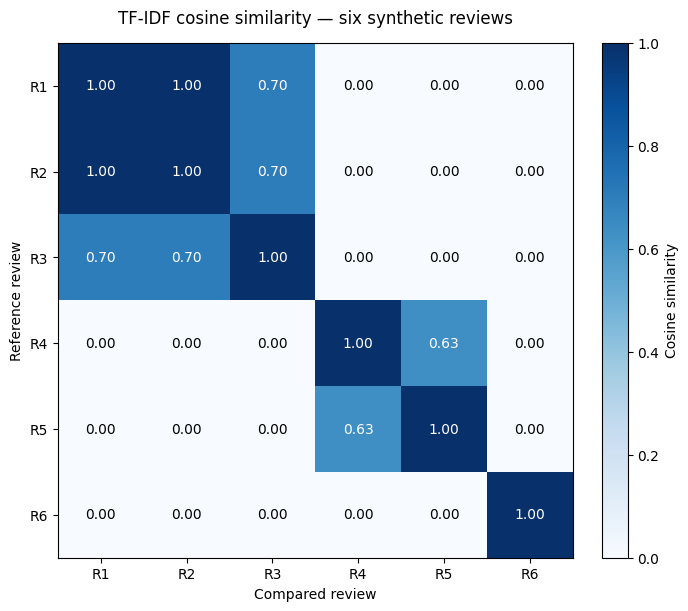

In [ ]:
similarity_matrix = cosine_similarity(review_matrix)  # Compare all six TF-IDF vectors.
similarity_table = pd.DataFrame(similarity_matrix, index=review_ids, columns=review_ids)  # Label both dimensions.
display(similarity_table.round(3))  # Inspect exact pairs before plotting.
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")  # Reserve enough room for labels.
heatmap = ax.imshow(similarity_matrix, cmap="Blues", vmin=0, vmax=1)  # Use one consistent similarity scale.
ax.set_xticks(range(len(review_ids)), labels=review_ids)  # Label the column documents.
ax.set_yticks(range(len(review_ids)), labels=review_ids)  # Label the row documents.
ax.set_xlabel("Compared review")  # Explain the horizontal dimension.
ax.set_ylabel("Reference review")  # Explain the vertical dimension.
ax.set_title("TF-IDF cosine similarity — six synthetic reviews", pad=14)  # State method and scope.
for row in range(len(review_ids)):  # Visit each row of the matrix.
    for column in range(len(review_ids)):  # Visit each cell in that row.
        score = similarity_matrix[row, column]  # Read the value being drawn.
        label_color = "white" if score > 0.55 else "black"  # Keep text readable on dark and light cells.
        ax.text(column, row, f"{score:.2f}", ha="center", va="center", color=label_color)  # Display the numeric score.
fig.colorbar(heatmap, ax=ax, label="Cosine similarity")  # Explain the color scale.
fig.savefig(output_dir / "week12_similarity_heatmap.png", dpi=180, bbox_inches="tight")  # Save the actual figure.
plt.show()  # Display the figure inside the notebook.

**Read the evidence:** R1 and R2 have identical unigram features; this does not mean BoW preserved their order. R3 includes **not**, but shared terms still produce similarity. Similarity retrieves related wording; it does not label sentiment.

To search for the most similar *other* review, remove the document's self-match before sorting.

In [ ]:
related_to_r1 = similarity_table.loc["R1"].drop("R1")  # Exclude the trivial self-match.
related_to_r1 = related_to_r1.sort_values(ascending=False)  # Put the highest scores first.
display(related_to_r1.to_frame("cosine_to_R1"))  # Expected: R2 first, then R3; the other scores are zero.

,cosine_to_R1
R2,1.000000
R3,0.699592
R4,0.000000
R5,0.000000
R6,0.000000


### **Step 11 — Search with a New Query**
The fitted vocabulary and IDF must remain unchanged. Use `transform`, not `fit_transform`, for the query. `ravel()` turns a one-row score matrix into a simple one-dimensional array.

**Expected:** `refund pending` ranks R4 first, then R5. Show only positive-scoring matches. A score is not a probability of correctness.

In [ ]:
query = "refund pending"  # Set the analyst's search words.
query_vector = vectorizer.transform([query])  # Reuse the fitted review feature space.
if query_vector.nnz == 0:  # Check whether any query terms are represented.
    print("No query terms match the fitted vocabulary.")  # Avoid inventing meaningful matches.
else:  # Compare only when the query has at least one feature.
    query_scores = cosine_similarity(query_vector, review_matrix).ravel()  # Compare against each reference review.
    search_results = review_table.copy()  # Keep row order aligned with the scores.
    search_results["cosine_similarity"] = query_scores  # Attach one score to each review.
    search_results = search_results[search_results["cosine_similarity"] > 0]  # Remove zero-overlap results.
    search_results = search_results.sort_values("cosine_similarity", ascending=False)  # Rank the candidates.
    display(search_results.reset_index(drop=True))  # Read the source text beside its score.

,review_id,text,cosine_similarity
0,R4,refund pending,1.000000
1,R5,payment failed refund pending,0.634086


#### Try a query containing only unseen words
**Expected:** zero stored features and a clear no-match explanation. Do not interpret it as neutral sentiment.

In [ ]:
unseen_query = "quantum telescope"  # Neither word appears in the fitted review vocabulary.
unseen_vector = vectorizer.transform([unseen_query])  # Preserve the existing nine-column feature space.
print("Recognized feature entries:", unseen_vector.nnz)  # Expected: 0.
if unseen_vector.nnz == 0:  # Identify the zero-vector condition explicitly.
    print("No vocabulary match. Review the query or the representation before searching.")  # Explain the limitation.
assert unseen_vector.shape[1] == review_matrix.shape[1]  # The column count must remain compatible.

Recognized feature entries: 0
No vocabulary match. Review the query or the representation before searching.


### **Step 12 — Understand Embedding Mechanics with Invented Coordinates**
These two-dimensional vectors are **hand-made teaching values, not learned embeddings**. They do not measure real semantic relationships. We choose nearby directions for refund/reimbursement to demonstrate what cosine comparison can do once dense vectors exist.

Real embeddings learn their values from data, generally have more dimensions, and require evaluation. This introductory lab deliberately avoids a large pretrained model download.

In [ ]:
illustrative_vectors = {  # Define invented coordinates only for this explanation.
    "refund": [1.0, 0.1],  # A manually chosen vector.
    "reimbursement": [0.9, 0.2],  # Chosen near refund for the illustration.
    "delivery": [0.1, 1.0],  # Chosen in another direction.
}
illustrative_table = pd.DataFrame.from_dict(illustrative_vectors, orient="index", columns=["coordinate_1", "coordinate_2"])  # Label the coordinates.
display(illustrative_table)  # Inspect the invented values directly.
illustrative_scores = cosine_similarity([illustrative_vectors["refund"]], illustrative_table.to_numpy())[0]  # Compare directions.
display(pd.DataFrame({"word": illustrative_table.index, "illustrative_cosine_to_refund": illustrative_scores}))  # Show mechanics, not measured semantics.

,coordinate_1,coordinate_2
refund,1.0,0.1
reimbursement,0.9,0.2
delivery,0.1,1.0


,word,illustrative_cosine_to_refund
0,refund,1.000000
1,reimbursement,0.992928
2,delivery,0.198020


#### Average two word vectors into one document vector
The example averages two known vectors. This loses order and does not demonstrate reliable handling of negation. **Expected:** `[0.55, 0.55]`.

In [ ]:
document_words = ["refund", "delivery"]  # Choose two words available in the invented table.
word_vectors = []  # Collect their vectors in document order.
for word in document_words:  # Read each chosen word.
    word_vectors.append(illustrative_vectors[word])  # Look up its known illustrative vector.
illustrative_document_vector = np.mean(word_vectors, axis=0)  # Average each coordinate across words.
print("Illustrative averaged document vector:", illustrative_document_vector)  # Expected: [0.55, 0.55].

Illustrative averaged document vector: [0.55 0.55]


### **Step 13 — Verify and Save the Results**
The checks below verify the hand calculation, feature dimensions, symmetry, and expected matches. They do not measure real-world search accuracy.

We export labelled matrices and representation notes. The notes include the fitted vocabulary and IDF values; CSV outputs alone do not constitute a deployed search system.

In [ ]:
assert count_table.loc["D3", "late"] == 2  # Verify a repeated word was counted correctly.
assert document_frequency["late"] == 2  # Verify df counts documents, not occurrences.
assert review_matrix.shape == (6, 9)  # Verify document and vocabulary counts.
assert np.allclose(similarity_matrix, similarity_matrix.T)  # Cosine pair comparisons should be symmetric.
assert np.allclose(np.diag(similarity_matrix), 1)  # Each nonzero review vector matches itself.
assert np.isclose(similarity_table.loc["R1", "R2"], 1)  # Verify word-order loss in unigram features.
assert search_results.iloc[0]["review_id"] == "R4"  # Verify the exact query match ranks first.
assert unseen_vector.nnz == 0  # Verify unseen words do not create new feature columns.
print("Passed: counts, df, dimensions, cosine structure, query ranking, and unseen-word handling.")  # Report only the checks performed.

Passed: counts, df, dimensions, cosine structure, query ranking, and unseen-word handling.


In [ ]:
count_table.to_csv(output_dir / "week12_small_count_matrix.csv", index_label="document_id")  # Save the hand-example counts.
review_table.to_csv(output_dir / "week12_reference_reviews.csv", index=False)  # Save source text with row identifiers.
review_feature_table.to_csv(output_dir / "week12_review_tfidf.csv", index_label="review_id")  # Save named TF-IDF features.
similarity_table.to_csv(output_dir / "week12_document_similarity.csv", index_label="review_id")  # Save pairwise scores.
package_versions = {}  # Collect versions for reproducibility.
for package in ["numpy", "pandas", "scikit-learn", "matplotlib"]:  # Record the libraries used in the lab.
    package_versions[package] = version(package)  # Read the installed version.
representation_notes = {  # Document how to interpret and reproduce these outputs.
    "data": "Synthetic teaching examples; three hand-calculation documents and six reference reviews",
    "tokenization": "Already lowercase, single-sentence examples split at whitespace; no stop-word removal",
    "tf": "Raw counts",
    "idf": "ln((1 + N) / (1 + df)) + 1",
    "normalization": "L2 for the final TF-IDF vectors",
    "review_vocabulary_in_order": review_features.tolist(),
    "review_idf_in_feature_order": vectorizer.idf_.tolist(),
    "embedding_demo": "Invented coordinates only; no model trained or evaluated",
    "package_versions": package_versions,
}
notes_path = output_dir / "week12_representation_notes.json"  # Name the reproducibility record.
notes_path.write_text(json.dumps(representation_notes, indent=2), encoding="utf-8")  # Save readable notes.
print("Saved labelled matrices, reference reviews, heatmap, and notes to:", output_dir.resolve())  # Confirm the output location.

Saved labelled matrices, reference reviews, heatmap, and notes to: /workspace/scratch/811a54b07379/deliverables/ba3002_week12_outputs
